In [84]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [85]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>

In [86]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [88]:
# importer les données
df = pd.read_csv('/content/drive/MyDrive/Car_Data (2).csv')

In [89]:
# Afficher les données
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


### Les données ont été scrapées de la page https://www.expat-dakar.com/voitures/dakar. Ce sont des données de vehicules en vente à Dakar. L'objectif de ce TP est de mettre en place un modèle classification qui en partant de certaines caractéristiques d'une voiture nous prédira si celle-ci est venante ou d'occassion.

In [6]:
# dimension des données
df.shape

(5507, 6)

In [7]:
# infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Marque           5507 non-null   object
 1   Année            5507 non-null   int64 
 2   Boite_Vitesse    5507 non-null   object
 3   Adresse          5507 non-null   object
 4   Prix             5507 non-null   int64 
 5   Venant_Occasion  5507 non-null   object
dtypes: int64(2), object(4)
memory usage: 258.3+ KB


### <font color = 'gold'>Exploration des données<font>

##### <font color = 'bisque'>Séléction des variables

In [90]:
# sélection des variables catégorielles en utilisant select_dtypes
cat_data = df.select_dtypes(include = 'object')
cat_data.head()

,Marque,Boite_Vitesse,Adresse,Venant_Occasion
0,Mitsubishi,Automatique,"Liberte 6,Dakar",Venant
1,Ford,Manuelle,"Yoff,Dakar",D'occasion
2,BMW,Automatique,"Cité Damel,Dakar",D'occasion
3,Ford,Automatique,"Almadies,Dakar",D'occasion
4,GMC,Automatique,"Hlm,Dakar",Venant


In [91]:
# sélection des variables quantitatives en utilisant select_dtypes
quant_data = df.select_dtypes(include = 'number')
quant_data.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


##### <font color = 'bisque'> Exploration des variables catégorielles

In [92]:
# splitter la variable Adresse en Quartier et Region
df[['Quartier', 'Region']] =df.Adresse.str.split(',', n = 1, expand = True)
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion,Quartier,Region
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant,Liberte 6,Dakar
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion,Yoff,Dakar
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion,Cité Damel,Dakar
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion,Almadies,Dakar
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant,Hlm,Dakar


In [93]:
# Supprimer les variable Adresse et Region
df.drop(['Adresse', 'Region'],axis = 1, inplace = True)
# df = df.drop(['Adresse', 'Region'],axis = 1)
df.head()

,Marque,Année,Boite_Vitesse,Prix,Venant_Occasion,Quartier
0,Mitsubishi,2017,Automatique,9750000,Venant,Liberte 6
1,Ford,2009,Manuelle,2500000,D'occasion,Yoff
2,BMW,2015,Automatique,15500000,D'occasion,Cité Damel
3,Ford,2013,Automatique,3800000,D'occasion,Almadies
4,GMC,2014,Automatique,7500000,Venant,Hlm


In [12]:
# Gérer les espaces sur la variable quartier
df.Quartier = df.Quartier.str.strip()
df.Quartier.unique()

array(['Liberte 6', 'Yoff', 'Cité Damel', 'Almadies', 'Hlm', 'VDN',
       'Plateau', 'Parcelles Assainies', 'Liberte 6 extension',
       'Colobane', 'Sicap foire', 'Fenêtre mermoz', 'Golf', 'Rufisque',
       'Nord foire', 'Ouest foire', 'Sacré-cœur', 'Sicap Liberté',
       'Hann maristes', 'Mbao', 'Gueule-Tapée', 'Amitié', 'Guediawaye',
       'Mermoz', 'Mamelles', 'Pikine', 'Cité keur gorgui', 'Grand-Yoff',
       'Grand-Dakar', 'Fann', 'Keur Massar', 'Hlm grand-yoff',
       'Avenue Bourguiba', 'Castor', 'Médina', 'Patte d‘oie', 'Dieuppeul',
       'Zac Mbao', 'Cambérène', 'Hann Bel-Air', 'Cité biagui', 'Dalifort',
       'Ngor', 'Point-e', 'Liberte 5', 'Bargny', 'Comico', 'Almadies 2',
       'Biscuiterie', 'Sud foire', 'Gibraltar', 'Diamaguene', 'Malika',
       'Tivaouane peulh', 'Bel air', 'Zone de captage', 'Djily mbaye',
       'Sicap Sacré-cœur', 'Yeumbeul', 'Ouakam', 'Liberte 2', 'Virage',
       'Thiaroye', 'Sebikotane', 'Niague', 'Sangalkam', 'Sicap mbao',
       'Liber

In [99]:
# renommer les variables
df.rename(columns= {'Boite_Vitesse': 'Transmission',
                    'Venant_Occasion': 'Etat'

}, inplace = True)
df.head()

,Marque,Année,Transmission,Prix,Etat,Quartier
0,Mitsubishi,2017,Automatique,9750000,Venant,Liberte 6
1,Ford,2009,Manuelle,2500000,D'occasion,Yoff
2,BMW,2015,Automatique,15500000,D'occasion,Cité Damel
3,Ford,2013,Automatique,3800000,D'occasion,Almadies
4,GMC,2014,Automatique,7500000,Venant,Hlm


In [100]:
# Réorganiser les variables
df= df[["Marque","Année", "Transmission", "Quartier", "Prix", "Etat"]]
df.head()

,Marque,Année,Transmission,Quartier,Prix,Etat
0,Mitsubishi,2017,Automatique,Liberte 6,9750000,Venant
1,Ford,2009,Manuelle,Yoff,2500000,D'occasion
2,BMW,2015,Automatique,Cité Damel,15500000,D'occasion
3,Ford,2013,Automatique,Almadies,3800000,D'occasion
4,GMC,2014,Automatique,Hlm,7500000,Venant


In [102]:
# Les valeurs uniques de la variable Etat
np.unique(df.Etat)

array(["D'occasion", 'Venant'], dtype=object)

In [103]:
# Les valeurs uniques de la variable transmission
np.unique(df.Transmission)

array(['Automatique', 'Manuelle', 'Tiptronic'], dtype=object)

In [104]:
cat_data = df.select_dtypes(include = 'object')
cat_data.head()

,Marque,Transmission,Quartier,Etat
0,Mitsubishi,Automatique,Liberte 6,Venant
1,Ford,Manuelle,Yoff,D'occasion
2,BMW,Automatique,Cité Damel,D'occasion
3,Ford,Automatique,Almadies,D'occasion
4,GMC,Automatique,Hlm,Venant


In [105]:
cat_data.describe().T

,count,unique,top,freq
Marque,5507,46,Ford,1391
Transmission,5507,3,Automatique,4675
Quartier,5507,122,Almadies,783
Etat,5507,2,Venant,2855


In [106]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  # plt.figure(figsize=(25,3))
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

In [22]:
# Countplots de toutes les variables
for col in cat_data.columns:
  countplot_func(col)

##### <font color = 'bisque'> Exploration des variables quantitatives

In [107]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,5507.0,2.014508e+03,3.089839e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,5507.0,1.110512e+07,1.619639e+07,1.0,4600000.0,7800000.0,12500000.0,779414131.0


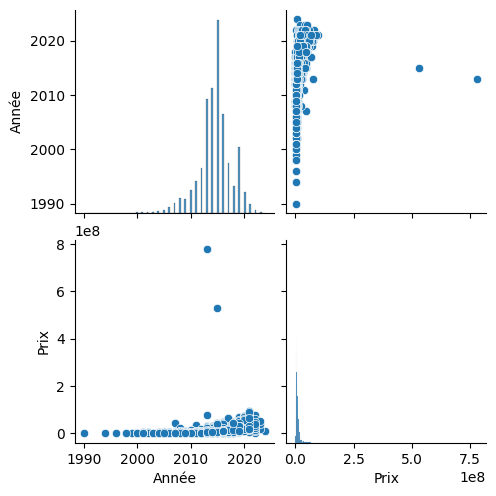

In [108]:
# pairplot
sns.pairplot(quant_data)
plt.show()

In [109]:
# matrice de corrélation
quant_data.corr()

,Année,Prix
Année,1.000000,0.399623
Prix,0.399623,1.000000


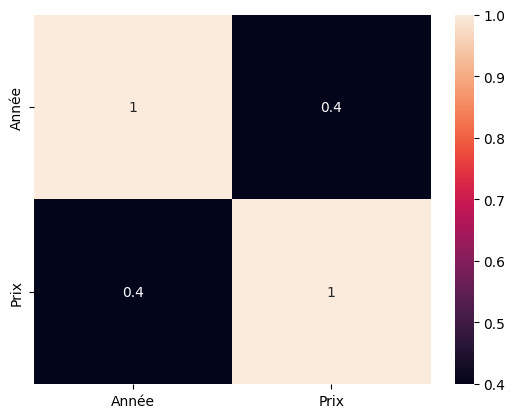

In [110]:
# matrice heatmap
sns.heatmap(quant_data.corr(), annot= True)
plt.show()

In [111]:
# fonction boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

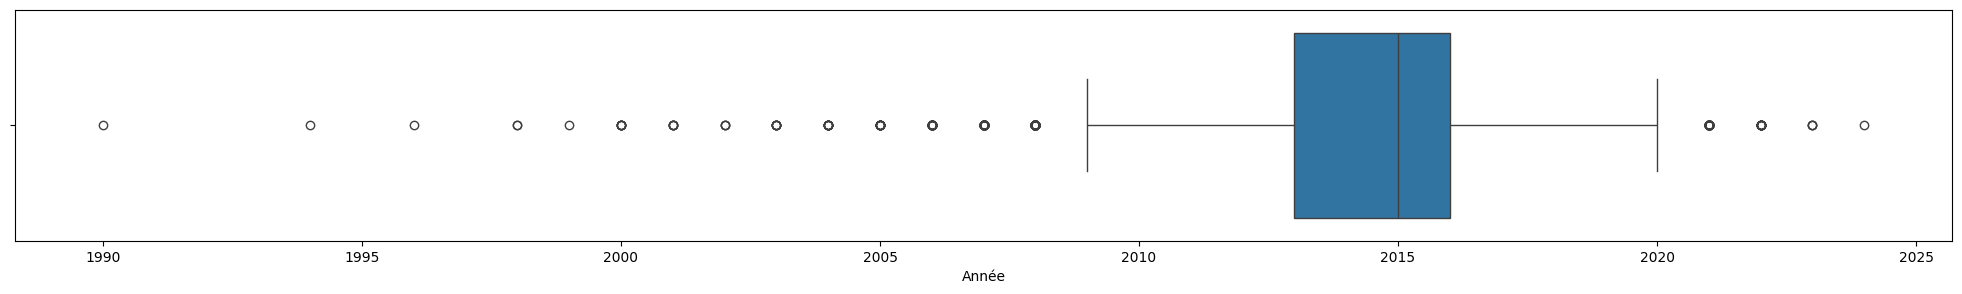

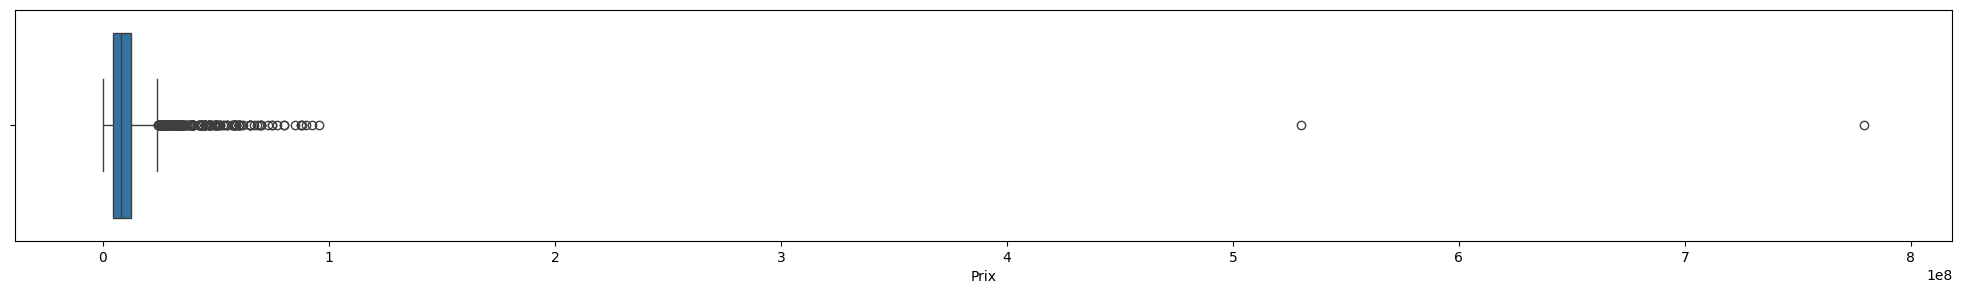

In [112]:
# boxplots des toutes les variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

### <font color = 'gold'>Preparation des données<font>



##### <font color = 'bisque'> Preparation des variables catégorielles

In [113]:
import joblib as jb
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = [] # {colonne: liste des valeurs uniques}
for col in cat_data.columns:
  uniques.append(list(np.unique(df[col])))

In [114]:
# faire un dumping de la liste des valeurs uniques
jb.dump(uniques, 'uniques.joblib')

['uniques.joblib']

In [115]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

encoder0 = LabelEncoder() # Marque
encoder1 = LabelEncoder() # Transmission
encoder2 = LabelEncoder() # Adresse
encoder3 = LabelEncoder() # Etat
encoders = [encoder0, encoder1, encoder2, encoder3]
for i in range(len(cat_data.columns)):
  encoders[i].fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoders[i].transform(df[cat_data.columns[i]]) # encoder les valeurs

In [116]:
# afficher df
df.head()

,Marque,Année,Transmission,Quartier,Prix,Etat
0,30,2017,0,85,9750000,1
1,13,2009,1,119,2500000,0
2,3,2015,0,47,15500000,0
3,13,2013,0,36,3800000,0
4,14,2014,0,74,7500000,1


In [117]:
# faire un dumping (télécharger) de la liste des encodeurs
jb.dump(encoders, 'encoders.joblib')

['encoders.joblib']

##### <font color = 'bisque'> Preparation des quantitatives

In [118]:
from sklearn.impute import KNNImputer

# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=3):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [119]:
# Application du traitement
for col in quant_data.columns:
  impute_func(df,col)

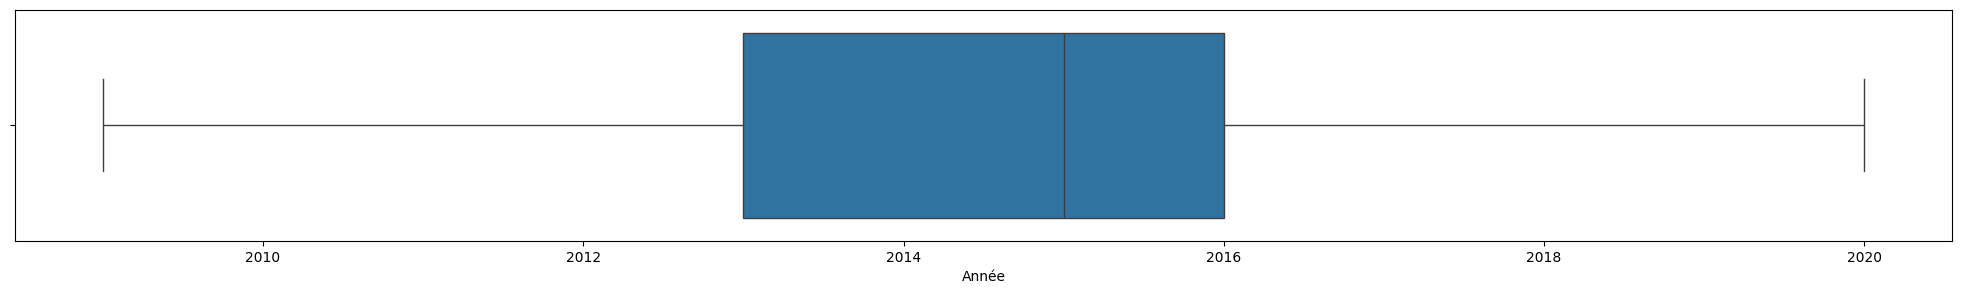

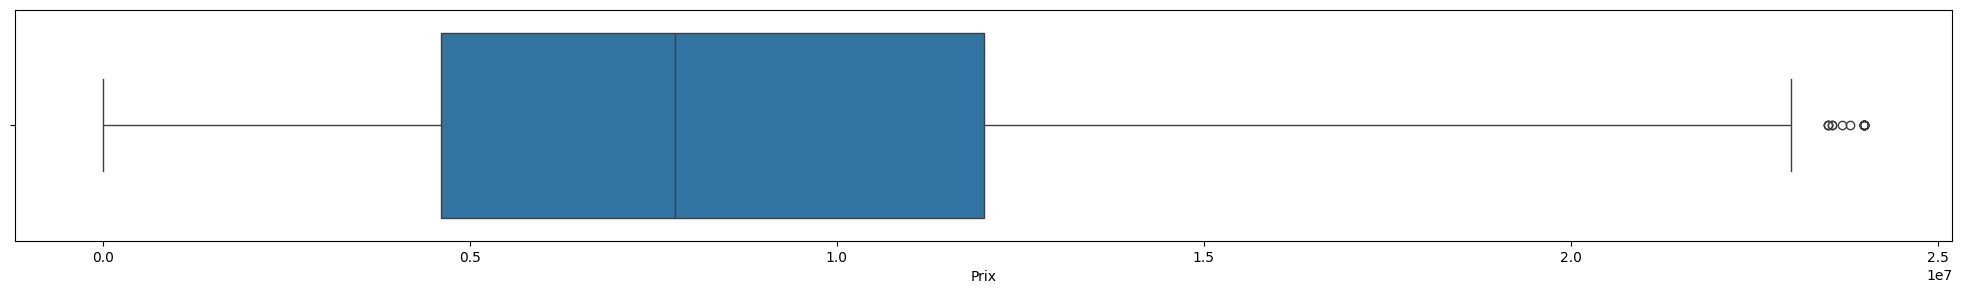

In [120]:
# boxplots des toutes les variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

##### <font color = 'bisque'> Fractionnement et normalisation

In [121]:
# Fractionner les données en X (Variables prédicteurs) et y (Variable cible)
x = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
x[:5], y[:5]

(array([[3.000e+01, 2.017e+03, 0.000e+00, 8.500e+01, 9.750e+06],
        [1.300e+01, 2.009e+03, 1.000e+00, 1.190e+02, 2.500e+06],
        [3.000e+00, 2.015e+03, 0.000e+00, 4.700e+01, 1.550e+07],
        [1.300e+01, 2.013e+03, 0.000e+00, 3.600e+01, 3.800e+06],
        [1.400e+01, 2.014e+03, 0.000e+00, 7.400e+01, 7.500e+06]]),
 array([1, 0, 0, 0, 1]))

In [144]:
# Importer MinMaxScaler
from sklearn.preprocessing import MinMaxScaler # x = (x -x_min) /(x_max - x_min)
# objet MinMax
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.66666667, 0.72727273, 0.        , 0.70247934, 0.40624998],
       [0.28888889, 0.        , 0.5       , 0.98347107, 0.10416663],
       [0.06666667, 0.54545455, 0.        , 0.38842975, 0.64583332],
       [0.28888889, 0.36363636, 0.        , 0.29752066, 0.1583333 ],
       [0.31111111, 0.45454545, 0.        , 0.61157025, 0.31249997]])

In [145]:
# faire un dumping (télécharger) du normaliseur
jb.dump(scaler, 'scaler.joblib')

['scaler.joblib']

In [146]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque modèle et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train,x_vt, y_train, y_vt = train_test_split(x, y, train_size = 0.8 ,random_state = 42) # 80% / 20%
x_val,x_test, y_val, y_test = train_test_split(x_vt, y_vt, train_size = 0.5, random_state = 42) # 10% / 10%

In [148]:
# dimension des données train
x_train.shape, y_train.shape

((4405, 5), (4405,))

In [149]:
# dimension des données de validation
x_val.shape, y_val.shape

((551, 5), (551,))

In [150]:
# dimension des données test
x_test.shape, y_test.shape

((551, 5), (551,))

### <font color = 'teal'>Random Forest<font>

In [127]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= 5)
# entrainer le modèle
grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [151]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'entropy',
 'max_depth': np.int64(9),
 'n_estimators': np.int64(50)}

In [152]:
from sklearn.ensemble import RandomForestClassifier
# Entrainer Random Forest en utilisant les paramètres optimaux
rf_model = RandomForestClassifier(criterion = 'gini',max_depth = 9,n_estimators = 60)
rf_model.fit(x_train,y_train)

RandomForestClassifier(max_depth=9, n_estimators=60)

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [153]:
# Accuracy et F1 score du modèle sur les données de validation
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  prec = precision_score(y_val, y_pred,  average='micro')
  rec = recall_score(y_val, y_pred, average='micro')
  return acc, f1, prec, rec

In [131]:
# Afficher les métriques
acc_rf, f1_rf, prec_rf, rec_rf = evaluation(rf_model)
print(f"Accuracy : {acc_rf:.2f}-- F1 score : {f1_rf:.2f} -- Precision : {prec_rf:.2f} -- Recall : {rec_rf:.2f}")

Accuracy : 0.81-- F1 score : 0.81 -- Precision : 0.81 -- Recall : 0.81


In [154]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = rf_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.87


In [155]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def heatmap_conf_matr(model):

  # y_pred:  prédictions du modèle sur les données validation
  y_pred = model.predict(x_val)
  # Confusion matrix
  cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1])

  # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
  disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                display_labels=['Occasion','Venant'])
  disp.plot() # Afficher la matrice de confusion
  plt.title('Matrice de confusion') # Définir le titre
  plt.show() # Afficher la figure

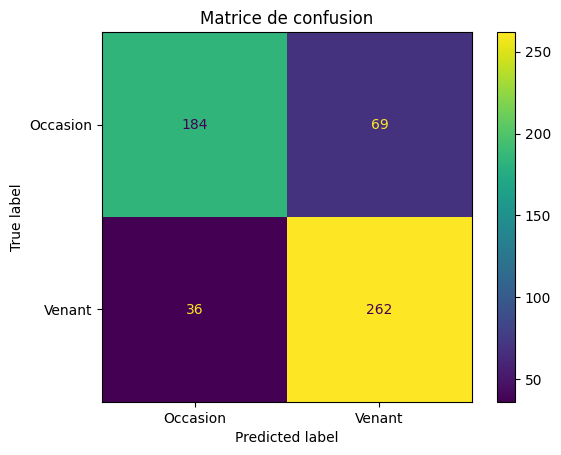

In [156]:
# visualiser
heatmap_conf_matr(rf_model)

In [157]:
# barplot de l'importance des variables
def barplot_feat_imp(rf_model):
  fig = px.bar(x = rf_model.feature_importances_, y = df.columns[:-1], color = df.columns[:-1])
  fig.show()

In [158]:
# Faire appel à la fonction
barplot_feat_imp(rf_model)

### <font color = 'teal'>Gradient Boosting<font>

In [137]:
# Recherche des paramètres optimaux pour Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
# dictionnaire des params
params_ = { "n_estimators":list(np.arange(10,100,10)),
              "max_depth":list(np.arange(3,15))}
# instantier le modèle Gradient Boost
gb = GradientBoostingClassifier()
# instantier le modèle gridsearch
grid_ = GridSearchCV(estimator=gb, param_grid=params_)
# entrainer le modèle
grid_.fit(x_train, y_train)

GridSearchCV(estimator=GradientBoostingClassifier(),
             param_grid={'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [185]:
# afficher les paramètres optimaux


In [159]:
# Entrainer Gradient Boosting en utilisant les paramètres optimaux max_depth = 5, n_estimators = 50
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(max_depth = 5, n_estimators = 50)
gb_model.fit(x_train, y_train)

GradientBoostingClassifier(max_depth=5, n_estimators=50)

##### <font color ='bisque'>Evaluation du Gradient Boosting<font>

In [160]:
# Afficher les métriques
acc_gb, f1_gb, prec_gb, rec_gb = evaluation(gb_model)
print(f"Accuracy : {acc_gb:.2f}-- F1 score : {f1_gb:.2f} -- Precision : {prec_gb:.2f} -- Recall : {rec_gb:.2f}")

Accuracy : 0.82-- F1 score : 0.82 -- Precision : 0.82 -- Recall : 0.82


In [161]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = gb_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.85


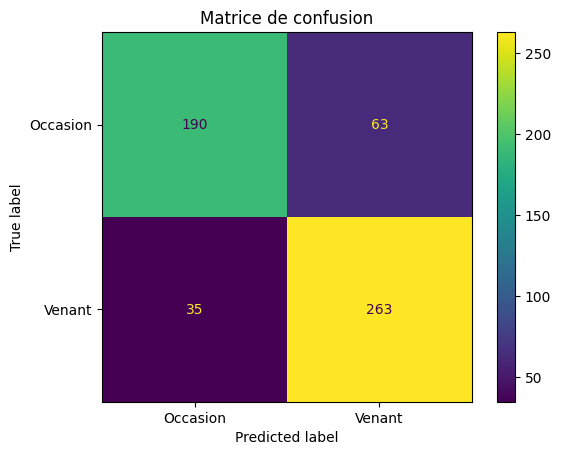

In [162]:
# matrice de confusion
heatmap_conf_matr(gb_model)

In [163]:
# barplot de l'importance des variables
barplot_feat_imp(gb_model)


### <font color = 'teal'>XGBoost<font>

In [164]:
# Recherche des paramètres optimaux pour XGBoost
from xgboost import XGBClassifier
# dictionnaire des params
params__ = {  "n_estimators":list(np.arange(10,100,10)),
              "max_depth":list(np.arange(3,15))}
# instantier le modèle XGBoost
xgb = XGBClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(estimator=xgb, param_grid=params__, cv= 5)
# entrainer le modèle
grid__.fit(x_train, y_train)

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None...
                                     n_jobs=None, num_parallel_tree=None, ...),
             param_grid={'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [165]:
# afficher les paramètres optimaux
grid__.best_params_

{'max_depth': np.int64(4), 'n_estimators': np.int64(20)}

In [166]:
from xgboost import XGBClassifier
# Entrainer le modèle en utilisant les paramètres optimaux
xgb_model = XGBClassifier(max_depth = 7, n_estimators = 20)
xgb_model.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=20,
              n_jobs=None, num_parallel_tree=None, ...)

##### <font color ='bisque'>Evaluation de XGBoost<font>

In [167]:
# Afficher les métriques
acc_xgb, f1_xgb, prec_xgb, rec_xgb = evaluation(xgb_model)
print(f"Accuracy : {acc_xgb:.2f}-- F1 score : {f1_xgb:.2f} -- Precision : {prec_xgb:.2f} -- Recall : {rec_xgb:.2f}")

Accuracy : 0.81-- F1 score : 0.81 -- Precision : 0.81 -- Recall : 0.81


In [168]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = xgb_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.88


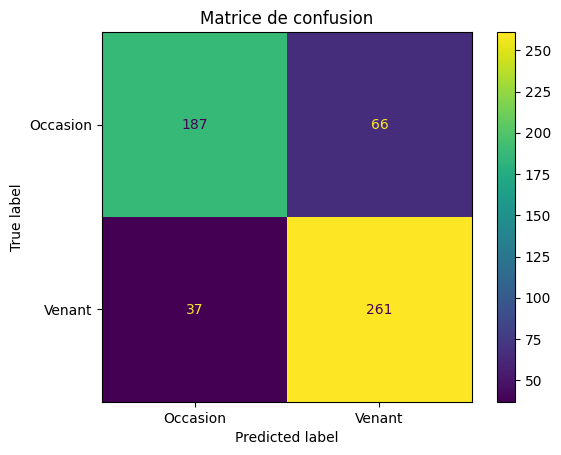

In [169]:
# matrice de confusion
heatmap_conf_matr(xgb_model)

In [170]:
# barplot de l'importance des variables
barplot_feat_imp(xgb_model)

K nearest neighbor (K-NN)

In [172]:
# Importer KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
# importer GridSearchCV
from sklearn.model_selection import GridSearchCV
# dictionnaire des params
params_knn = {'n_neighbors': list(np.arange(2,31))}
# instantier le modèle KNN
knn = KNeighborsClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=knn, param_grid=params_knn, cv= 5)
# entrainer le modèle
grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [np.int64(2), np.int64(3), np.int64(4),
                                         np.int64(5), np.int64(6), np.int64(7),
                                         np.int64(8), np.int64(9), np.int64(10),
                                         np.int64(11), np.int64(12),
                                         np.int64(13), np.int64(14),
                                         np.int64(15), np.int64(16),
                                         np.int64(17), np.int64(18),
                                         np.int64(19), np.int64(20),
                                         np.int64(21), np.int64(22),
                                         np.int64(23), np.int64(24),
                                         np.int64(25), np.int64(26),
                                         np.int64(27), np.int64(28),
                                         np.int64(29), np.int64(30)]})

In [174]:
# k optimal
k = grid.best_params_['n_neighbors']
# Instantier le modèle
knn_model = KNeighborsClassifier(n_neighbors = k )
# Entrainer le modèle
knn_model.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=np.int64(22))

In [175]:
# afficher les paramètres optimaux
grid.best_params_

{'n_neighbors': np.int64(22)}

In [176]:
# Afficher les métriques
acc_knn, f1_knn, prec_knn, rec_knn = evaluation(knn_model)
print(f"Accuracy : {acc_knn:.2f}-- F1 score : {f1_knn:.2f} -- Precision : {prec_knn:.2f} -- Recall : {rec_knn:.2f}")

Accuracy : 0.80-- F1 score : 0.80 -- Precision : 0.80 -- Recall : 0.80


In [177]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = knn_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.81


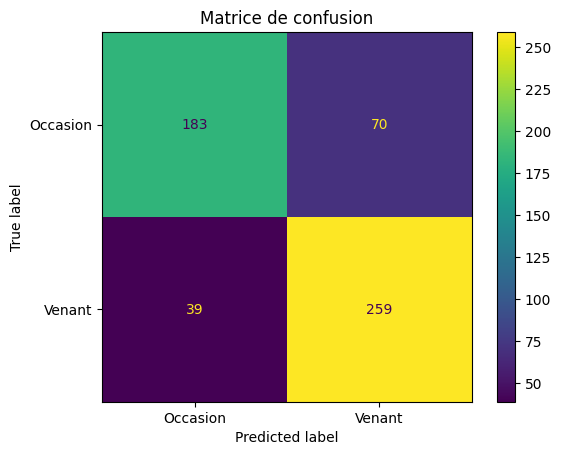

In [178]:
# matrice de confusion
heatmap_conf_matr(knn_model)

#### <font color = 'teal'>Régression Logistique<font>

In [181]:
# Recherche des paramètres optimaux pour la Régression Logistique
from sklearn.linear_model import LogisticRegression
# dictionnaire des params
params_lg = {"C":np.logspace(-3,3,7), "penalty": ['l2'], 'solver': ['lbfgs']}
# instantier le modèle
lg = LogisticRegression(max_iter=1000)
# instantier le modèle gridsearch
grid_ = GridSearchCV(estimator=lg, param_grid=params_lg, cv= 5)
# entrainer le modèle
grid_.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03]),
                         'penalty': ['l2'], 'solver': ['lbfgs']})

In [183]:
# afficher les paramètres optimaux
grid_.best_params_

{'C': np.float64(0.1), 'penalty': 'l2', 'solver': 'lbfgs'}

In [184]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model = LogisticRegression(max_iter=1000, **grid_.best_params_)
lg_model.fit(x_train,y_train)

LogisticRegression(C=np.float64(0.1), max_iter=1000)

##### <font color ='bisque'>Evaluation de la Régression Logistique<font>

In [185]:
# Afficher les métriques
acc_lg, f1_lg, prec_lg, rec_lg = evaluation(lg_model)
print(f"Accuracy : {acc_lg:.2f}-- F1 score : {f1_lg:.2f} -- Precision : {prec_lg:.2f} -- Recall : {rec_lg:.2f}")

Accuracy : 0.79-- F1 score : 0.79 -- Precision : 0.79 -- Recall : 0.79


In [186]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = lg_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.78


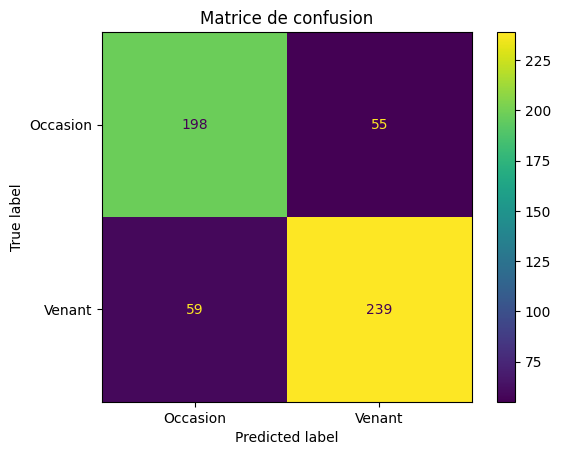

In [187]:
# matrice de confusion
heatmap_conf_matr(lg_model)

#### <font color = 'teal'>Support Vector Machine (SVM)<font>

In [188]:
# Recherche des paramètres optimaux pour le SVM
from sklearn.svm import SVC
# dictionnaire des params
params_svm = {'C': np.logspace(-1,3,5), 'kernel':['linear','rbf']}
# instantier le modèle svm
svm = SVC()
# instantier le modèle gridsearch
grid__svm = GridSearchCV(estimator=svm, param_grid=params_svm, cv= 5)
# entrainer le modèle
grid__svm.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': array([1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03]),
                         'kernel': ['linear', 'rbf']})

In [189]:
# afficher les paramètres optimaux
grid__svm.best_params_

{'C': np.float64(100.0), 'kernel': 'rbf'}

In [190]:
# Entrainer le SVM en utilisant les paramètres optimaux
svm_model = SVC(**grid__svm.best_params_)
svm_model.fit(x_train, y_train)

SVC(C=np.float64(100.0))

##### <font color ='bisque'>Evaluation du SVM<font>

In [191]:
# Afficher les métriques
acc_svm, f1_svm, prec_svm, rec_svm = evaluation(svm_model)
print(f"Accuracy : {acc_svm:.2f}-- F1 score : {f1_svm:.2f} -- Precision : {prec_svm:.2f} -- Recall : {rec_svm:.2f}")

Accuracy : 0.80-- F1 score : 0.80 -- Precision : 0.80 -- Recall : 0.80


In [85]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = svm_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.82


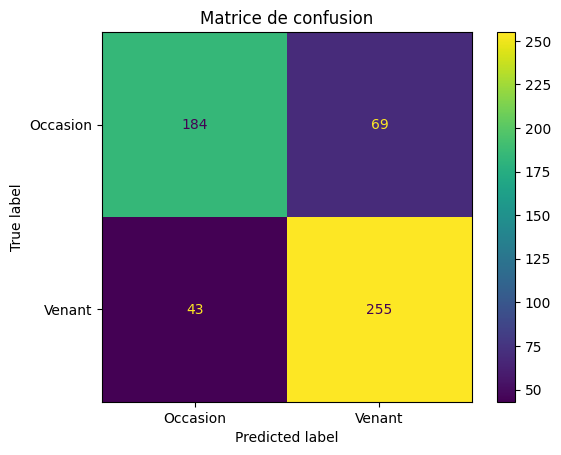

In [192]:
# matrice de confusion
heatmap_conf_matr(svm_model)

#### <font color = 'teal'>Arbre de décision (Decision Tree)<font>

In [193]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
params_dt = {'criterion':['gini','entropy'],'max_depth':list(np.arange(3,15))}
# instantier le modèle
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__dt = GridSearchCV(estimator=dt, param_grid=params_dt, cv= 5)
# entrainer le modèle
grid__dt.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)]})

In [194]:
# afficher les paramètres optimaux
grid__dt.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(4)}

In [195]:
# Entrainer le Decision Tree en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(**grid__dt.best_params_)
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=np.int64(4))

In [197]:
# Afficher les métriques
acc_dt, f1_dt, prec_dt, rec_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt:.2f}-- F1 score : {f1_dt:.2f} -- Precision : {prec_dt:.2f} -- Recall : {rec_dt:.2f}")

Accuracy : 0.81-- F1 score : 0.81 -- Precision : 0.81 -- Recall : 0.81


In [198]:
# Accuracy sur les données train -- Vérifier le comportement du modèle en terme apprentissage
y_pred_train = dt_model.predict(x_train)
print(f"Le f1 score est : {f1_score(y_pred_train, y_train, average = 'micro'): .2f}")

Le f1 score est :  0.81


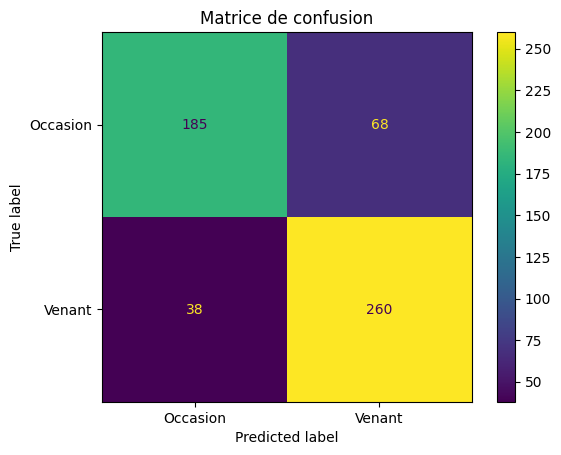

In [199]:
# matrice de confusion
heatmap_conf_matr(dt_model)

In [200]:
# barplot de l'importance des variables
barplot_feat_imp(dt_model)

In [201]:
# Diagramme en barre de comparaison des modèles
list_f1 = [f1_rf, f1_gb, f1_xgb, f1_knn, f1_lg, f1_svm, f1_dt]
list_models_names = ['RF', 'GB', 'XGB', 'KNN', 'LogReg', 'SVM', 'DT']
fig = px.bar(x = list_models_names, y = list_f1, color = list_models_names, text_auto = True)
fig.show()

In [202]:
# télécharger le modèle le plus performant
jb.dump(gb_model, 'gb_model.joblib')

['gb_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [203]:
# echantillons de 10
x_test_10 = x_test[:10]
y_test_10 = y_test[: 10]
y_pred_10 = gb_model.predict(x_test_10)
class_names = ['Occasion', 'Venant']
for i in range(10):
  print(f"Prédiction {str(i+1)} :{class_names[y_pred_10[i]]} |  True Label : {class_names[y_test_10[i]]} ")

Prédiction 1 :Occasion |  True Label : Occasion 
Prédiction 2 :Venant |  True Label : Venant 
Prédiction 3 :Occasion |  True Label : Occasion 
Prédiction 4 :Venant |  True Label : Venant 
Prédiction 5 :Occasion |  True Label : Venant 
Prédiction 6 :Occasion |  True Label : Occasion 
Prédiction 7 :Venant |  True Label : Venant 
Prédiction 8 :Venant |  True Label : Occasion 
Prédiction 9 :Occasion |  True Label : Venant 
Prédiction 10 :Venant |  True Label : Occasion 


### <font color = 'bisque'>Deploiement du modèle avec Gradio<font>

In [204]:
!pip install gradio

In [208]:
# Fonction de prédiction
import gradio as gr
import joblib as jb
import pandas as pd
import numpy as np
# importer les encodeurs
encoders = jb.load('encoders.joblib')
# importer les valeurs uniques
uniques = jb.load('uniques.joblib')
# importer le normaliseur
scaler = jb.load('scaler.joblib')
# importer le modèle
gb = jb.load('gb_model.joblib')

# noms des classes
clasnames = uniques[3]
# fonction de prédiction simple
def Pred_func(marque, annee, transmission, quartier, prix):

  # Encoder les valeurs catégorielles
  marque = encoders[0].transform([marque])[0]
  transmission = encoders[1].transform([transmission])[0]
  quartier = encoders[2].transform([quartier])[0]
   # Construire le vecteur de variables dans l'ordre d'entrainement : Marque, Année, Transmission, Prix, Quartier
  x_new = np.array([marque, annee, transmission, quartier, prix])
  x_new = x_new.reshape(1,-1) # convert en un 2D array
  # Normaliser les données
  x_new = scaler.transform(x_new)
  # Prédire
  y_pred = gb_model.predict(x_new)
  return clasnames[y_pred[0]]

In [209]:
# Fonction de prédiction multiple
def Pred_func_csv(file):
  # Lire le fichier csv
  df = pd.read_csv(file)
  predictions = []
  # Boucle sur les lignes du dataframe
  for row in df.iloc[:, :].values:
    # prédiction simple
    y_pred = Pred_func(row[0], row[1], row[2], row[3], row[4], row[5])
    predictions.append(y_pred)

  df['Etat'] = predictions
  df.to_csv('predictions.csv', index = False)
  return 'predictions.csv'

In [212]:
# définir les blocks
demo = gr.Blocks(theme='shivi/calm_seafoam')

# Créer les inputs
inputs = [gr.Dropdown(choices=uniques[0], label='Marque'),
          gr.Number(label='Année'),
          gr.Dropdown(choices=uniques[1], label='Transmission'),
          gr.Dropdown(choices=uniques[2], label='Quartier'),
          gr.Number(label='Prix'),
          ]
# Créer les outputs
outputs = gr.Textbox(label='Etat du véhicule')
# Créer l'interface 1
interface1 = gr.Interface(fn = Pred_func,
                         inputs = inputs,
                         outputs = outputs,
                         title="Prédire l'état du véhicule avec une entrée",
                         description = """Ce modèle de machine permet de prédire l'état du véhicule en partant
                        de la marque, de l'année, de la transmission, du quartier et du prix.
                         """)
# Créer l'interface 2
interface2 = gr.Interface(fn = Pred_func_csv,
                         inputs = gr.File(label='Importer un fichier csv'),
                          outputs = gr.File(label='Télécharger un fichier csv'),
                         title="Prédire l'état du véhicule avec plusieurs entrées",
                         description = """Ce modèle de machine permet de prédire l'état du véhicule en partant
                        de la marque, de l'année, de la transmission, du quartier et du prix..
                         """)

# faire un tabbing des interfaces
with demo:
  gr.TabbedInterface([interface1, interface2], ['Simple Prediction', 'Prédiction multiple'])

# lancer l'interface
demo.launch(share= True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0d20b0cb131d6bb254.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
